Choose an option:
1. Load existing audio file: load_and_plot_spectrogram('path/to/your/audio.wav')
2. Generate synthetic sound: generate_synthetic_sound_spectrogram()
10000


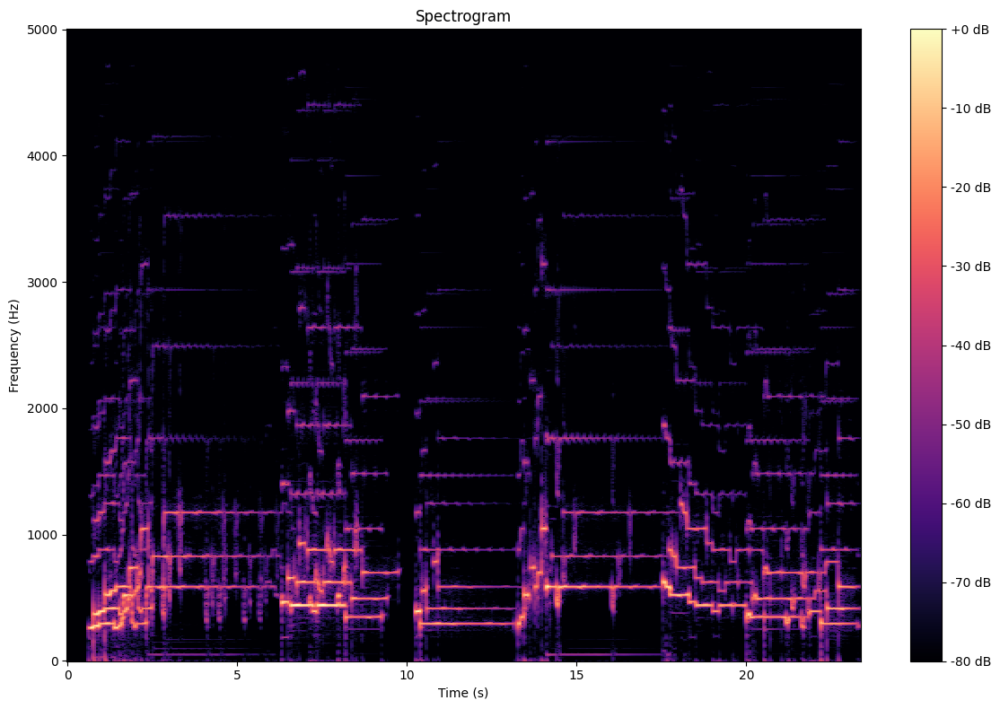

(array([ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
        -1.0019316e-05, -1.8691439e-05, -2.2372944e-05],
       shape=(233750,), dtype=float32),
 10000,
 array([[-80.      , -80.      , -80.      , ..., -79.85312 , -72.85463 ,
         -69.53244 ],
        [-80.      , -80.      , -80.      , ..., -75.47705 , -68.443306,
         -69.807076],
        [-80.      , -80.      , -80.      , ..., -72.8052  , -66.33911 ,
         -71.35151 ],
        ...,
        [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
         -80.      ],
        [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
         -80.      ],
        [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
         -80.      ]], shape=(1025, 457), dtype=float32))

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy import signal
import soundfile as sf

# Option 1: Load an existing audio file
def load_and_plot_spectrogram(audio_file_path):
    """
    Load an audio file and create its spectrogram
    """
    # Load audio file
    y, sr = librosa.load(audio_file_path, sr=10000)

    print(sr)
    
    # Create spectrogram using Short-Time Fourier Transform (STFT)
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    
    # Plot the spectrogram
    plt.figure(figsize=(12, 8))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar(format='%+2.0f dB')
    plt.title('Spectrogram')
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()
    
    return y, sr, S_db

# Example usage:
print("Choose an option:")
print("1. Load existing audio file: load_and_plot_spectrogram('path/to/your/audio.wav')")
print("2. Generate synthetic sound: generate_synthetic_sound_spectrogram()")

# Uncomment the line below to run the synthetic sound example
load_and_plot_spectrogram('play-1.mp3')


In [11]:
import numpy as np
import librosa
import librosa.display
import plotly.graph_objs as go
import plotly.offline as pyo
from IPython.display import HTML

def spectrogram_with_playhead(audio_path, sr=None):
    # 1) load audio + compute spectrogram
    y, sr = librosa.load(audio_path, sr=sr)
    D    = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    times= librosa.frames_to_time(np.arange(S_db.shape[1]), sr=sr)
    freqs= librosa.fft_frequencies(sr=sr)

    # 2) build two traces: heatmap + playhead line (initially at t=0)
    heatmap = go.Heatmap(
        x=times, y=freqs, z=S_db,
        colorscale='Viridis', showscale=True
    )
    playhead = go.Scatter(
        x=[0, 0],
        y=[freqs.min(), freqs.max()],
        mode='lines',
        line=dict(color='red', width=2),
        name='Playhead'
    )

    fig = go.Figure(data=[heatmap, playhead])
    fig.update_layout(
        title='Spectrogram with synchronized playhead',
        xaxis_title='Time (s)',
        yaxis_title='Frequency (Hz)',
        margin=dict(l=50, r=20, t=50, b=50)
    )

    # 3) export to a div
    graph_div = pyo.plot(fig, include_plotlyjs=True, output_type='div')

    # 4) assemble HTML+JS
    html = f"""
    {graph_div}
    <audio id="player" controls src="{audio_path}" style="width: 100%; margin-top:10px;"></audio>
    <script>
      var audio = document.getElementById('player');
      // find the most recently added Plotly plot
      var plot = document.querySelectorAll('.js-plotly-plot');
      plot = plot[plot.length - 1];

      audio.ontimeupdate = function() {{
        var t = audio.currentTime;
        // update second trace (index=1) x‐coords to [t, t]
        Plotly.restyle(plot, {{ x: [[t, t]] }}, [1]);
      }};
    </script>
    """

    display(HTML(html))


# Usage:
spectrogram_with_playhead('groov.mp3')

In [ ]:
import numpy as np
import librosa
import soundfile as sf
from sklearn.decomposition import NMF
import os

def universal_separate(input_path, n_components=3, sr=None):
    """
    Unsupervised separation of ANY sounds via NMF.
    
    Args:
      input_path (str): Path to your audio file (wav, mp3, flac, …).
      n_components (int): How many “sources” to extract.
      sr (int or None): target sampling rate (None to preserve original).
    """
    # create a folder for the separated stems
    os.makedirs("stems", exist_ok=True)

    # 1. Load as mono to simplify
    y, sr = librosa.load(input_path, sr=sr, mono=True)
    
    # 2. STFT > magnitude
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))
    
    # 3. NMF on magnitude spectrogram
    model = NMF(
        n_components=n_components,
        init='nndsvd',
        random_state=0,
        max_iter=500
    )
    W = model.fit_transform(S)   # shape: (freq_bins,  n_components)
    H = model.components_        # shape: (n_components, time_frames)
    
    # 4. For each component, reconstruct and write out
    for i in range(n_components):
        # estimated mag spectrogram of component i
        S_i = np.outer(W[:, i], H[i, :])
        # re-apply the original phase
        D_i = S_i * np.exp(1j * np.angle(librosa.stft(y, n_fft=2048, hop_length=512)))
        # back to time domain
        y_i = librosa.istft(D_i, hop_length=512)
        # save
        sf.write(f"nmf_stems/nmf_source_{i+1}.wav", y_i, sr)
        print(f"Written nmf_source_{i+1}.wav")

universal_separate("plainte1.mp3", n_components=4)

Written nmf_source_1.wav
Written nmf_source_2.wav
Written nmf_source_3.wav
Written nmf_source_4.wav


In [98]:
import numpy as np
import librosa
import torch
import soundfile as sf
from demucs.pretrained import get_model
from demucs.apply import apply_model
import os

# create a folder for the separated stems
os.makedirs("stems", exist_ok=True)

# 1. Load the pretrained Demucs model
model = get_model("mdx_extra")    # or "demucs", "mdx_extra", etc.
model.cpu().eval()               # inference mode

# 2. Load your audio with Librosa (preserve stereo if present)
#    mono=False → y.shape = (n_channels, n_samples) if stereo,
#                  or (n_samples,) if mono.
y, sr = librosa.load("groov.mp3", sr=model.samplerate, mono=False)

# Debug: Print original audio info
print(f"Original audio shape: {y.shape}")
print(f"Sample rate: {sr}")
print(f"Audio dimensions: {y.ndim}D")
if y.ndim == 1:
    print("Audio type: MONO")
elif y.ndim == 2:
    print(f"Audio type: STEREO ({y.shape[0]} channels)")

# 3. Ensure stereo audio: (2, time) for htdemucs_6s model
if y.ndim == 1:
    print("Converting mono to stereo...")
    # Mono audio: duplicate to create stereo
    y = np.stack([y, y], axis=0)    # make it (2, samples)

print(f"Final audio shape: {y.shape}")
print(f"Ready for Demucs: {'✓' if y.shape[0] == 2 else '✗'}")

# 4. Build a batch tensor: (batch=1, channels, time)
audio = torch.from_numpy(y).unsqueeze(0)

# 5. Separate: returns (1, n_sources, channels, time)
with torch.no_grad():
    sources = apply_model(model, audio, device="mps")

# 6. Save each separated stem using soundfile
#    model.sources is a list like ["drums","bass","other","vocals"]
sources = sources.squeeze(0)  # (n_sources, channels, time)
for src, name in zip(sources, model.sources):
    # src: Tensor (channels, time) → NumPy (time, channels)
    arr = src.cpu().numpy().T
    # in subfolder
    sf.write(f"stems/{name}.wav", arr, sr)
    print(f"Written: {name}.wav")

Original audio shape: (6525753,)
Sample rate: 44100
Audio dimensions: 1D
Audio type: MONO
Converting mono to stereo...
Final audio shape: (2, 6525753)
Ready for Demucs: ✓
Written: drums.wav
Written: bass.wav
Written: other.wav
Written: vocals.wav


In [ ]:
import numpy as np
import librosa
import soundfile as sf
import os
from scipy.ndimage import uniform_filter1d

def split_audio_smart(audio_path, output_dir="chunks"):
    """
    Split audio into natural sound phrases using:
    1. Beat-based chunks (by musical bars)
    2. Phrase-based chunks (amplitude envelope analysis)
    """
    
    # Create output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # Load audio
    y, sr = librosa.load(audio_path, sr=None)
    duration = len(y) / sr
    print(f"Audio: {duration:.1f}s, {sr}Hz")
    
    # ====== 1. BEAT-BASED CHUNKS ======
    print("\n🥁 BEAT-BASED CHUNKS (by musical bars)")
    try:
        tempo, beats = librosa.beat.beat_track(y=y, sr=sr, units='time')
        beats_per_chunk = 16  # 4 bars of 4 beats each
        beat_chunks = []
        
        for i in range(0, len(beats) - beats_per_chunk, beats_per_chunk):
            start_time = beats[i]
            end_time = beats[min(i + beats_per_chunk, len(beats) - 1)]
            
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            chunk = y[start_sample:end_sample]
            
            chunk_path = f"{output_dir}/beat_chunk_{i//beats_per_chunk:03d}.wav"
            sf.write(chunk_path, chunk, sr)
            beat_chunks.append(chunk_path)
            print(f"  🎵  Bar {i//beats_per_chunk+1}: {start_time:.1f}s - {end_time:.1f}s: {chunk_path}")
            
    except Exception as e:
        print(f"  ❌ Beat detection failed: {e}")
        beat_chunks = []
    
    # ====== 2. PHRASE-BASED CHUNKS (Smart Amplitude Envelope) ======
    print("\n🎤 PHRASE-BASED CHUNKS (amplitude envelope analysis)")
    try:
        # Calculate multiple envelope features
        frame_length = 1024
        hop_length = 256
        
        # 1. RMS energy (overall loudness)
        rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]
        
        # 2. Spectral centroid (brightness)
        spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=sr, hop_length=hop_length)[0]
        
        # Get time frames
        times = librosa.frames_to_time(np.arange(len(rms)), sr=sr, hop_length=hop_length)
        
        # Smooth RMS with a rolling window to get cleaner envelope
        rms_smooth = uniform_filter1d(rms, size=5)
        
        # Find dynamic threshold based on RMS distribution
        rms_sorted = np.sort(rms_smooth)
        low_threshold = rms_sorted[int(0.2 * len(rms_sorted))]   # 20th percentile
        high_threshold = rms_sorted[int(0.7 * len(rms_sorted))]  # 70th percentile
        
        print(f"  🎚️  RMS thresholds: low={low_threshold:.4f}, high={high_threshold:.4f}")
        
        # Detect phrase boundaries using state machine
        SILENT, QUIET, ACTIVE = 0, 1, 2
        state = SILENT
        phrase_starts = []
        phrase_ends = []
        current_start = 0
        
        for i, (time, rms_val) in enumerate(zip(times, rms_smooth)):
            if state == SILENT:
                if rms_val > low_threshold:
                    current_start = time
                    state = QUIET
                    
            elif state == QUIET:
                if rms_val > high_threshold:
                    state = ACTIVE
                elif rms_val < low_threshold:
                    state = SILENT
                    
            elif state == ACTIVE:
                if rms_val < low_threshold:
                    # End of phrase
                    if time - current_start > 1.0:  # minimum 1 second phrase
                        phrase_starts.append(current_start)
                        phrase_ends.append(time)
                    state = SILENT
        
        # Handle final phrase if song ends while active
        if state in [QUIET, ACTIVE] and duration - current_start > 1.0:
            phrase_starts.append(current_start)
            phrase_ends.append(duration)
        
        # Create phrase chunks
        phrase_chunks = []
        for i, (start_time, end_time) in enumerate(zip(phrase_starts, phrase_ends)):
            # Add small padding
            padded_start = max(0, start_time - 0.1)
            padded_end = min(duration, end_time + 0.1)
            
            start_sample = int(padded_start * sr)
            end_sample = int(padded_end * sr)
            chunk = y[start_sample:end_sample]
            
            chunk_path = f"{output_dir}/phrase_{i+1:03d}.wav"
            sf.write(chunk_path, chunk, sr)
            phrase_chunks.append(chunk_path)
            print(f"  🎤  Phrase {i+1}: {start_time:.1f}s - {end_time:.1f}s ({end_time-start_time:.1f}s): {chunk_path}")
        
    except Exception as e:
        print(f"  ❌ Phrase detection failed: {e}")
        phrase_chunks = []
    
    # ====== SUMMARY ======
    print(f"\n📊 SUMMARY:")
    print(f"  Beat chunks: {len(beat_chunks)}")
    print(f"  Phrase chunks: {len(phrase_chunks)}")
    print(f"  All saved to: {output_dir}/")
    
    return {
        'beat': beat_chunks,
        'phrase': phrase_chunks
    }

# Test with your audio
chunks = split_audio_smart("stems/drums.wav")


Audio: 148.0s, 44100Hz

🥁 BEAT-BASED CHUNKS (by musical bars)
  🎵  Bar 1: 0.6s - 5.6s: chunks/beat_chunk_000.wav
  🎵  Bar 2: 5.6s - 10.4s: chunks/beat_chunk_001.wav
  🎵  Bar 3: 10.4s - 15.4s: chunks/beat_chunk_002.wav
  🎵  Bar 4: 15.4s - 20.3s: chunks/beat_chunk_003.wav
  🎵  Bar 5: 20.3s - 25.3s: chunks/beat_chunk_004.wav
  🎵  Bar 6: 25.3s - 30.2s: chunks/beat_chunk_005.wav
  🎵  Bar 7: 30.2s - 35.2s: chunks/beat_chunk_006.wav
  🎵  Bar 8: 35.2s - 40.0s: chunks/beat_chunk_007.wav
  🎵  Bar 9: 40.0s - 45.0s: chunks/beat_chunk_008.wav
  🎵  Bar 10: 45.0s - 49.9s: chunks/beat_chunk_009.wav
  🎵  Bar 11: 49.9s - 54.9s: chunks/beat_chunk_010.wav
  🎵  Bar 12: 54.9s - 59.8s: chunks/beat_chunk_011.wav
  🎵  Bar 13: 59.8s - 64.7s: chunks/beat_chunk_012.wav
  🎵  Bar 14: 64.7s - 69.6s: chunks/beat_chunk_013.wav
  🎵  Bar 15: 69.6s - 74.6s: chunks/beat_chunk_014.wav
  🎵  Bar 16: 74.6s - 79.5s: chunks/beat_chunk_015.wav
  🎵  Bar 17: 79.5s - 84.5s: chunks/beat_chunk_016.wav
  🎵  Bar 18: 84.5s - 89.4s: chun

In [ ]:
# 🎛️ PHRASE LENGTH TUNING GUIDE
print("🎛️ Parameters to control phrase length:")
print("  📏 min_phrase_duration: Minimum seconds per phrase (1.0 = shorter phrases, 5.0 = longer)")
print("  🎚️ Thresholds: How sensitive to volume changes")
print("     - low_percentile (0.2 = sensitive, 0.4 = less sensitive)")
print("     - high_percentile (0.7 = sensitive, 0.9 = less sensitive)")
print("  🌊 smoothing_window: How smooth the envelope (3 = choppy, 10 = smooth)")
print("  ⏱️ frame_size: Time resolution (512 = detailed, 2048 = broader)")

def split_audio_tunable(audio_path, output_dir="chunks_tuned",
                       min_phrase_duration=2.0,    # 🎛️ MAIN CONTROL: longer = fewer, longer phrases
                       low_percentile=0.3,         # 🎚️ Volume sensitivity (higher = less sensitive)
                       high_percentile=0.8,        # 🎚️ Volume sensitivity (higher = less sensitive) 
                       smoothing_window=7,         # 🌊 Envelope smoothness (higher = smoother)
                       frame_size=2048):            # ⏱️ Time resolution (higher = broader)
    """
    Tunable phrase detection with user controls!
    
    🎛️ MAIN CONTROLS:
    - min_phrase_duration: 1.0-10.0s (higher = longer phrases)
    - low_percentile: 0.1-0.5 (higher = less sensitive, longer phrases)
    - high_percentile: 0.6-0.9 (higher = less sensitive, longer phrases)
    - smoothing_window: 3-15 (higher = smoother, longer phrases)
    """
    
    os.makedirs(output_dir, exist_ok=True)
    y, sr = librosa.load(audio_path, sr=None)
    duration = len(y) / sr
    
    print(f"\n🎵 Processing: {duration:.1f}s audio")
    print(f"🎛️ Settings: min_duration={min_phrase_duration}s, thresholds=({low_percentile:.1f},{high_percentile:.1f}), smooth={smoothing_window}")
    
    # Calculate RMS with tunable parameters
    hop_length = frame_size // 2
    rms = librosa.feature.rms(y=y, frame_length=frame_size, hop_length=hop_length)[0]
    times = librosa.frames_to_time(np.arange(len(rms)), sr=sr, hop_length=hop_length)
    
    # Smooth with tunable window
    rms_smooth = uniform_filter1d(rms, size=smoothing_window)
    
    # Dynamic thresholds with user control
    rms_sorted = np.sort(rms_smooth)
    low_threshold = rms_sorted[int(low_percentile * len(rms_sorted))]
    high_threshold = rms_sorted[int(high_percentile * len(rms_sorted))]
    
    print(f"🎚️ Calculated thresholds: low={low_threshold:.4f}, high={high_threshold:.4f}")
    
    # State machine for phrase detection
    SILENT, QUIET, ACTIVE = 0, 1, 2
    state = SILENT
    phrase_starts = []
    phrase_ends = []
    current_start = 0
    
    for i, (time, rms_val) in enumerate(zip(times, rms_smooth)):
        if state == SILENT:
            if rms_val > low_threshold:
                current_start = time
                state = QUIET
                
        elif state == QUIET:
            if rms_val > high_threshold:
                state = ACTIVE
            elif rms_val < low_threshold:
                state = SILENT
                
        elif state == ACTIVE:
            if rms_val < low_threshold:
                # End of phrase - check minimum duration
                if time - current_start > min_phrase_duration:
                    phrase_starts.append(current_start)
                    phrase_ends.append(time)
                state = SILENT
    
    # Handle final phrase
    if state in [QUIET, ACTIVE] and duration - current_start > min_phrase_duration:
        phrase_starts.append(current_start)
        phrase_ends.append(duration)
    
    # Create phrase chunks
    phrase_chunks = []
    for i, (start_time, end_time) in enumerate(zip(phrase_starts, phrase_ends)):
        # Small padding
        padded_start = max(0, start_time - 0.1)
        padded_end = min(duration, end_time + 0.1)
        
        start_sample = int(padded_start * sr)
        end_sample = int(padded_end * sr)
        chunk = y[start_sample:end_sample]
        
        chunk_path = f"{output_dir}/phrase_{i+1:02d}_{end_time-start_time:.1f}s.wav"
        sf.write(chunk_path, chunk, sr)
        phrase_chunks.append(chunk_path)
        print(f"  🎤 Phrase {i+1}: {start_time:.1f}s - {end_time:.1f}s ({end_time-start_time:.1f}s): {chunk_path}")
    
    print(f"\n📊 Result: {len(phrase_chunks)} phrases, avg length: {np.mean([end-start for start,end in zip(phrase_starts, phrase_ends)]):.1f}s")
    return phrase_chunks

# 🎛️ EXPERIMENT WITH THESE SETTINGS:

print("\n🔬 EXPERIMENT 1: SHORT PHRASES (more, smaller chunks)")
short_chunks = split_audio_tunable("stems/drums.wav", "chunks_short",
                                  min_phrase_duration=0.1,    # ⬇️ Shorter minimum
                                  low_percentile=0.2,         # ⬇️ More sensitive
                                  high_percentile=0.7,        # ⬇️ More sensitive
                                  smoothing_window=5)         # ⬇️ Less smooth

print("\n🔬 EXPERIMENT 2: LONG PHRASES (fewer, bigger chunks)")  
long_chunks = split_audio_tunable("stems/drums.wav", "chunks_long",
                                 min_phrase_duration=0.1,     # ⬆️ Longer minimum
                                 low_percentile=0.4,          # ⬆️ Less sensitive
                                 high_percentile=0.9,         # ⬆️ Less sensitive
                                 smoothing_window=10)         # ⬆️ More smooth


🎛️ Parameters to control phrase length:
  📏 min_phrase_duration: Minimum seconds per phrase (1.0 = shorter phrases, 5.0 = longer)
  🎚️ Thresholds: How sensitive to volume changes
     - low_percentile (0.2 = sensitive, 0.4 = less sensitive)
     - high_percentile (0.7 = sensitive, 0.9 = less sensitive)
  🌊 smoothing_window: How smooth the envelope (3 = choppy, 10 = smooth)
  ⏱️ frame_size: Time resolution (512 = detailed, 2048 = broader)

🔬 EXPERIMENT 1: SHORT PHRASES (more, smaller chunks)

🎵 Processing: 148.0s audio
🎛️ Settings: min_duration=0.1s, thresholds=(0.2,0.7), smooth=5
🎚️ Calculated thresholds: low=0.0103, high=0.0803
  🎤 Phrase 1: 0.0s - 1.1s (1.1s): chunks_short/phrase_01_1.1s.wav
  🎤 Phrase 2: 1.1s - 1.4s (0.3s): chunks_short/phrase_02_0.3s.wav
  🎤 Phrase 3: 1.5s - 1.8s (0.3s): chunks_short/phrase_03_0.3s.wav
  🎤 Phrase 4: 2.2s - 3.4s (1.2s): chunks_short/phrase_04_1.2s.wav
  🎤 Phrase 5: 3.6s - 3.9s (0.3s): chunks_short/phrase_05_0.3s.wav
  🎤 Phrase 6: 4.6s - 5.9s (1.3s):

In [1]:
import numpy as np
import librosa
import soundfile as sf
import os
import matplotlib.pyplot as plt
from skimage.segmentation import felzenszwalb, mark_boundaries
from skimage.util import img_as_ubyte
from scipy.ndimage import label as cc_label, generate_binary_structure


def split_audio_felzenszwalb_2d(
    audio_path,
    output_dir="chunks3",
    n_fft=2048,
    hop_length=512,
    scale=150,
    sigma=3,
    min_size=20,
    min_area_pixels=200,
    min_time_frames=3,
    min_energy_ratio=1e-4,
    max_shapes=None,
):
    """
    True 2D Felzenszwalb segmentation on the STFT magnitude.
    - Segments the spectrogram (freq x time) into irregular shapes
    - For each connected shape, masks the complex STFT and reconstructs audio using original phase
    - Saves each shape as its own audio chunk
    """
    os.makedirs(output_dir, exist_ok=True)

    # 1) Load audio
    y, sr = librosa.load(audio_path, sr=None)

    # 2) Complex STFT and magnitude
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, window="hann", center=True)
    S = np.abs(D)  # (freq_bins, time_frames)

    # 3) Log scale + normalize to 0..255 for segmentation
    S_db = librosa.amplitude_to_db(S + 1e-12, ref=np.max)
    S_db_norm = (S_db - S_db.min()) / max(1e-12, (S_db.max() - S_db.min()))
    img = img_as_ubyte(S_db_norm)  # 2D grayscale image

    # 4) Felzenszwalb segmentation on 2D spectrogram image
    segments = felzenszwalb(img, scale=scale, sigma=sigma, min_size=min_size)

    # 5) For each label, extract connected 2D shapes and reconstruct audio via masked STFT
    total_energy = float(S.sum()) + 1e-12
    T = S.shape[1]
    times = librosa.frames_to_time(np.arange(T), sr=sr, hop_length=hop_length)

    structure = generate_binary_structure(2, 2)  # 8-connectivity
    saved_paths = []
    shape_index = 0

    unique_labels = np.unique(segments)
    for lab in unique_labels:
        mask_lab = (segments == lab)
        cc, num = cc_label(mask_lab, structure=structure)
        for comp_id in range(1, num + 1):
            comp_mask = (cc == comp_id)
            area = int(comp_mask.sum())
            if area < min_area_pixels:
                continue

            # Energy and basic extents
            energy = float(S[comp_mask].sum())
            if energy / total_energy < min_energy_ratio:
                continue

            time_mask = np.any(comp_mask, axis=0)
            if time_mask.sum() < min_time_frames:
                continue
            t0 = int(np.argmax(time_mask))
            t1 = int(len(time_mask) - np.argmax(time_mask[::-1]) - 1)

            freq_mask = np.any(comp_mask, axis=1)
            f0 = int(np.argmax(freq_mask))
            f1 = int(len(freq_mask) - np.argmax(freq_mask[::-1]) - 1)

            # Mask complex STFT
            D_masked = D * comp_mask.astype(D.dtype)
            y_rec = librosa.istft(D_masked, hop_length=hop_length, length=len(y))

            # Slice to the time span of this shape for a concise chunk
            start_samp = int(times[t0] * sr)
            end_samp = min(len(y), int(times[min(t1 + 1, T - 1)] * sr))
            y_seg = y_rec[start_samp:end_samp]
            if y_seg.size == 0:
                continue

            # Normalize to avoid clipping
            peak = np.max(np.abs(y_seg))
            if peak > 0:
                y_seg = 0.98 * y_seg / peak

            shape_index += 1
            filename = f"felzen_shape_{shape_index:03d}_t{(t1 - t0 + 1)}_f{(f1 - f0 + 1)}.wav"
            out_path = os.path.join(output_dir, filename)
            sf.write(out_path, y_seg, sr)
            saved_paths.append(out_path)

            if max_shapes is not None and shape_index >= max_shapes:
                break
        if max_shapes is not None and shape_index >= max_shapes:
            break

    # 6) Save a visualization overlay
    try:
        plt.figure(figsize=(12, 6))
        plt.imshow(S_db_norm, aspect='auto', origin='lower', cmap='magma')
        plt.axis('off')
        plt.title('Felzenszwalb segmentation boundaries on STFT (freq x time)')
        plt.imshow(mark_boundaries(np.dstack([S_db_norm]*3), segments), aspect='auto', origin='lower')
        plt.tight_layout()
        plt.savefig(os.path.join(output_dir, "felzenszwalb_2d_shapes.png"), dpi=160)
        plt.close()
    except Exception as e:
        print(f"Could not save visualization: {e}")

    print(f"Saved {len(saved_paths)} shape chunks to {output_dir}/")
    return saved_paths

# Example (commented):
shapes = split_audio_felzenszwalb_2d("clips/chop.mp3")



Saved 22 shape chunks to chunks3/
